# TP 2 Deep Learning


In [1]:
import copy
import random
import re
import time
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

SEED = 42


def fixer_graine(graine):
    random.seed(graine)
    np.random.seed(graine)
    torch.manual_seed(graine)


fixer_graine(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Calcul sur :", device)

Calcul sur : cuda


## Étape 1 - Nettoyage et prétraitement

Mêmes choix qu'au TP1 : on garde les répliques d'au moins 5 mots, on enlève les doublons et on garde les 5 personnages qui parlent le plus.

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texte = urllib.request.urlopen(URL).read().decode("utf-8")


def parser_repliques(txt):
    lignes = []
    for bloc in txt.split("\n\n"):
        parties = bloc.strip().split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({"locuteur": entete.group(1).strip(),
                           "replique": " ".join(p.strip() for p in parties[1:]).strip()})
    return pd.DataFrame(lignes)


df = parser_repliques(texte)
d = df[df["replique"].str.split().str.len() >= 5].drop_duplicates(subset="replique")
principaux = d["locuteur"].value_counts().head(5).index
donnees = d[d["locuteur"].isin(principaux)]

print(donnees["locuteur"].value_counts())
print(len(donnees), "exemples")

locuteur
GLOUCESTER        196
DUKE VINCENTIO    165
ROMEO             141
PETRUCHIO         133
MENENIUS          126
Name: count, dtype: int64
761 exemples


### Découpage train / validation / test

On vise à peu près 64 % / 16 % / 20 %, avec le même test qu'au TP1.

In [3]:
X_reste, X_test, y_reste, y_test = train_test_split(
    donnees["replique"], donnees["locuteur"],
    test_size=0.2, stratify=donnees["locuteur"], random_state=SEED)

X_train, X_val, y_train, y_val = train_test_split(
    X_reste, y_reste,
    test_size=0.2, stratify=y_reste, random_state=SEED)   # 20 % de 80 % = 16 % du total

for nom, X in [("train", X_train), ("validation", X_val), ("test", X_test)]:
    print(f"{nom:10s} : {len(X):5d} exemples ({len(X) / len(donnees):.0%})")

# les noms des personnages deviennent des entiers
encodeur = LabelEncoder().fit(y_train)
classes = encodeur.classes_
ytr, yva, yte = (encodeur.transform(y) for y in (y_train, y_val, y_test))

train      :   486 exemples (64%)
validation :   122 exemples (16%)
test       :   153 exemples (20%)


**Pourquoi un jeu de validation fixe, et pas le test ?** Il sert à choisir C et à arrêter l'entraînement (early stopping). Refaire une validation croisée coûterait cher avec les réseaux. Si on choisissait sur le test, le score final serait trop optimiste.

## Étape 2 - Représentation

### 2.1 Pour le ML : TF-IDF

In [4]:
MOTIF = r"(?u)\b\w[\w']*\b"
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2,
                        sublinear_tf=True, token_pattern=MOTIF)

Xtr = tfidf.fit_transform(X_train)   # train : on apprend le vocabulaire et on transforme
Xva = tfidf.transform(X_val)         # validation : transform seulement
Xte = tfidf.transform(X_test)        # test : transform seulement

print(Xtr.shape, Xva.shape, Xte.shape)

(486, 2938) (122, 2938) (153, 2938)


### 2.2 Pour le DL : chaque réplique devient une suite d'identifiants

In [5]:
PAD, UNK = 0, 1


def tokeniser(texte):
    return re.findall(MOTIF, texte.lower())


compte = Counter(mot for replique in X_train for mot in tokeniser(replique))   # sur le train seulement
vocab = {"<pad>": PAD, "<unk>": UNK}
for mot, n in compte.most_common():
    if n >= 2:
        vocab[mot] = len(vocab)

longueurs = [len(tokeniser(r)) for r in X_train]
print("Taille du vocabulaire :", len(vocab))
print("Longueurs (médiane, 90 %, 95 %, max) :", np.percentile(longueurs, [50, 90, 95, 100]))

Taille du vocabulaire : 1335
Longueurs (médiane, 90 %, 95 %, max) : [ 18.  81. 112. 582.]


In [6]:
MAX_LEN = 120   # environ 95 % des répliques font moins de 120 mots (voir les longueurs au-dessus)


def encoder(texte):
    ids = [vocab.get(mot, UNK) for mot in tokeniser(texte)][:MAX_LEN]
    return ids + [PAD] * (MAX_LEN - len(ids))


def creer_loader(X, y, melanger=False):
    jeu = TensorDataset(torch.tensor([encoder(r) for r in X], dtype=torch.long),
                        torch.tensor(y, dtype=torch.long))
    return DataLoader(jeu, batch_size=32, shuffle=melanger)


loader_train = creer_loader(X_train, ytr, melanger=True)
loader_val = creer_loader(X_val, yva)
loader_test = creer_loader(X_test, yte)

xb, yb = next(iter(loader_train))
print(xb.shape, yb.shape)
print(xb[0])

torch.Size([32, 120]) torch.Size([32])
tensor([  43,  153,    1,   44, 1215,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
           0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0])


**Vocabulaire, `<unk>`, `<pad>`, `MAX_LEN` :** le vocabulaire est construit sur le train seul pour éviter une fuite. `<unk>` remplace les mots inconnus ou trop rares, `<pad>` complète les répliques courtes pour avoir la même longueur. `MAX_LEN = 120` garde en entier environ 95 % des répliques du train (95e percentile : 112 mots) ; les plus longues (jusqu'à 582) sont coupées.

## Étape 3 - Modèles

### 3.1 Les modèles ML (pour comparer)

In [7]:
resultats = {}

dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
resultats["Baseline"] = {"f1_val": f1_score(yva, dummy.predict(Xva), average="macro"),
                         "preds_test": [dummy.predict(Xte)], "parametres": 0, "temps (s)": 0.0}

fabriques = {
    "LogisticRegression": lambda C: LogisticRegression(C=C, class_weight="balanced", max_iter=5000),
    "LinearSVC": lambda C: LinearSVC(C=C, class_weight="balanced", random_state=SEED),
}
for nom, fabrique in fabriques.items():
    debut = time.perf_counter()
    essais = []
    for C in [0.1, 0.3, 1, 3, 10]:
        m = fabrique(C).fit(Xtr, ytr)
        score = f1_score(yva, m.predict(Xva), average="macro")   # on choisit C sur la validation
        essais.append((score, C, m))
    score, C, m = max(essais, key=lambda e: e[0])
    resultats[nom] = {"f1_val": score, "preds_test": [m.predict(Xte)],
                      "parametres": m.coef_.size + m.intercept_.size,
                      "temps (s)": time.perf_counter() - debut}
    print(f"{nom} : C = {C}, F1 macro validation = {score:.3f}")

LogisticRegression : C = 10, F1 macro validation = 0.578
LinearSVC : C = 1, F1 macro validation = 0.617


### 3.2 Modèle DL 1 : embeddings + moyenne + MLP

Chaque mot passe par un embedding, on fait la moyenne sur les vrais mots (sans le padding), puis un petit MLP donne un score par personnage.

Formes : (B, L) → (B, L, d) → (B, d) → (B, nombre de classes)

In [8]:
class MoyenneMLP(nn.Module):
    def __init__(self, taille_vocab, n_classes, d=64, h=64, dropout=0.4):
        super().__init__()
        self.emb = nn.Embedding(taille_vocab, d, padding_idx=PAD)
        self.mlp = nn.Sequential(
            nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout), nn.Linear(h, n_classes))

    def forward(self, x):                       # x : (B, L)
        e = self.emb(x)                         # (B, L, d)
        masque = (x != PAD).unsqueeze(-1)       # (B, L, 1)
        somme = (e * masque).sum(dim=1)         # (B, d)
        moyenne = somme / masque.sum(dim=1).clamp(min=1)
        return self.mlp(moyenne)                # (B, n_classes)

### 3.3 Modèle DL 2 : GRU bidirectionnel

La moyenne ne tient pas compte de l'ordre des mots. Le GRU, lui, lit la réplique dans l'ordre (et dans les deux sens).

In [9]:
class ModeleGRU(nn.Module):
    def __init__(self, taille_vocab, n_classes, d=64, h=64, dropout=0.4):
        super().__init__()
        self.emb = nn.Embedding(taille_vocab, d, padding_idx=PAD)
        self.gru = nn.GRU(d, h, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.sortie = nn.Linear(2 * h, n_classes)   # les 2 sens sont collés : 2 * h

    def forward(self, x):                           # x : (B, L)
        longueurs = (x != PAD).sum(dim=1).clamp(min=1).cpu()
        paquet = nn.utils.rnn.pack_padded_sequence(   # pour que le GRU saute le padding
            self.emb(x), longueurs, batch_first=True, enforce_sorted=False)
        _, h_n = self.gru(paquet)                   # (2, B, h) : un état par sens
        etat = torch.cat([h_n[0], h_n[1]], dim=1)
        return self.sortie(self.drop(etat))

### 3.4 Boucle d'entraînement

Pour chaque batch : forward, loss, backward, puis mise à jour des poids. On arrête quand le F1 sur la validation ne s'améliore plus pendant quelques époques (early stopping).

In [10]:
poids = compute_class_weight("balanced", classes=np.arange(len(classes)), y=ytr)
poids = torch.tensor(poids, dtype=torch.float32).to(device)


@torch.no_grad()
def predire_logits(modele, loader):
    modele.eval()
    return torch.cat([modele(xb.to(device)).cpu() for xb, _ in loader])


def entrainer(modele, epoques=40, lr=1e-3, patience=5):
    modele.to(device)
    critere = nn.CrossEntropyLoss(weight=poids)
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=1e-2)
    meilleur_f1, meilleur_etat, attente, historique = -1.0, None, 0, []

    for epoque in range(epoques):
        modele.train()
        total = 0.0
        for xb, yb in loader_train:
            xb, yb = xb.to(device), yb.to(device)
            loss = critere(modele(xb), yb)
            optimiseur.zero_grad()   # on remet les gradients à zéro
            loss.backward()          # rétropropagation
            optimiseur.step()        # mise à jour des poids
            total += loss.item() * len(yb)

        logits = predire_logits(modele, loader_val)
        loss_val = critere(logits.to(device), torch.tensor(yva).to(device)).item()
        f1_val = f1_score(yva, logits.argmax(dim=1).numpy(), average="macro")
        historique.append({"train": total / len(ytr), "validation": loss_val, "f1_val": f1_val})

        if f1_val > meilleur_f1:
            meilleur_f1, meilleur_etat, attente = f1_val, copy.deepcopy(modele.state_dict()), 0
        else:
            attente += 1
            if attente >= patience:
                break

    modele.load_state_dict(meilleur_etat)       # on revient à la meilleure époque
    return meilleur_f1, historique

In [11]:
GRAINES = [0, 1, 2]     # le résultat dépend de l'initialisation, donc on teste 3 graines
historiques = {}

for nom, classe_modele in [("Moyenne + MLP", MoyenneMLP), ("GRU", ModeleGRU)]:
    scores, preds, durees = [], [], []
    for graine in GRAINES:
        fixer_graine(graine)
        modele = classe_modele(len(vocab), len(classes))
        debut = time.perf_counter()
        f1_val, historique = entrainer(modele)
        durees.append(time.perf_counter() - debut)
        scores.append(f1_val)
        preds.append(predire_logits(modele, loader_test).argmax(dim=1).numpy())
        historiques[(nom, graine)] = historique
        print(f"{nom}, graine {graine} : F1 validation = {f1_val:.3f} ({len(historique)} époques)")
    resultats[nom] = {"f1_val": np.mean(scores), "preds_test": preds,
                      "parametres": sum(p.numel() for p in modele.parameters()),
                      "temps (s)": np.mean(durees)}

Moyenne + MLP, graine 0 : F1 validation = 0.452 (40 époques)
Moyenne + MLP, graine 1 : F1 validation = 0.340 (12 époques)
Moyenne + MLP, graine 2 : F1 validation = 0.459 (31 époques)
GRU, graine 0 : F1 validation = 0.394 (26 époques)
GRU, graine 1 : F1 validation = 0.326 (10 époques)
GRU, graine 2 : F1 validation = 0.411 (40 époques)


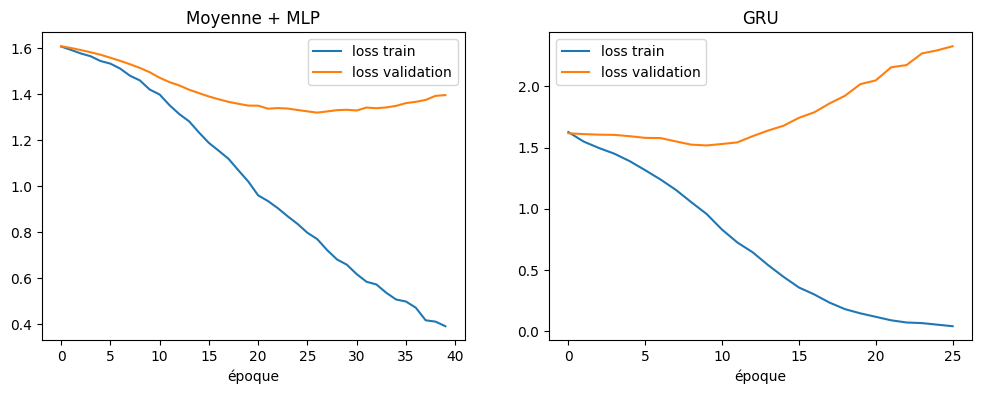

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, nom in zip(axes, ["Moyenne + MLP", "GRU"]):
    h = pd.DataFrame(historiques[(nom, GRAINES[0])])
    ax.plot(h["train"], label="loss train")
    ax.plot(h["validation"], label="loss validation")
    ax.set_title(nom)
    ax.set_xlabel("époque")
    ax.legend()
plt.show()

> **Questions.** À partir de quand voit-on du sur-apprentissage sur les courbes ? Que font ici le dropout, `weight_decay` et l'early stopping ?
>
> *Réponses :*
>
> - **Sur-apprentissage (graine 0, époques comptées à partir de 0) :** pour Moyenne + MLP, la loss validation atteint son minimum vers l'époque 26 puis remonte à partir de l'époque 31 environ, alors que la loss train continue de baisser. Pour le GRU, c'est beaucoup plus tôt et plus net : minimum vers l'époque 9, puis elle remonte de 1,5 à 2,3 pendant que la loss train tombe presque à 0. Le GRU apprend le train par cœur.
> - **Dropout (0,4) :** pendant l'entraînement, il met au hasard une partie des neurones à zéro. Le modèle ne peut pas compter sur quelques neurones précis, donc il généralise mieux.
> - **`weight_decay` :** il pousse les poids à rester petits (proche d'une pénalité L2), ce qui évite un modèle trop compliqué.
> - **Early stopping :** on garde l'époque avec le meilleur F1 sur la validation, et on arrête si ça ne s'améliore plus pendant 5 époques. On ne garde donc pas un modèle qui a sur-appris.

## Étape 4 - Évaluation sur le test

In [13]:
lignes = []
for nom, r in resultats.items():
    f1 = [f1_score(yte, p, average="macro", zero_division=0) for p in r["preds_test"]]
    moyenne = lambda fonction, **options: np.mean([fonction(yte, p, **options) for p in r["preds_test"]])
    macro = dict(average="macro", zero_division=0)
    lignes.append({
        "modèle": nom,
        "F1 val": r["f1_val"],
        "accuracy": moyenne(accuracy_score),
        "précision macro": moyenne(precision_score, **macro),
        "rappel macro": moyenne(recall_score, **macro),
        "F1 macro": np.mean(f1),
        "écart-type F1": np.std(f1),
        "F1 weighted": moyenne(f1_score, average="weighted", zero_division=0),
        "paramètres": r["parametres"],
        "temps (s)": r["temps (s)"],
    })
tableau = pd.DataFrame(lignes).sort_values("F1 val", ascending=False)
tableau.round(3)

,modèle,F1 val,accuracy,précision macro,rappel macro,F1 macro,écart-type F1,F1 weighted,paramètres,temps (s)
2,LinearSVC,0.617,0.621,0.625,0.621,0.619,0.000,0.623,14695,0.195
1,LogisticRegression,0.578,0.608,0.611,0.605,0.606,0.000,0.609,14695,2.747
3,Moyenne + MLP,0.417,0.447,0.455,0.448,0.437,0.074,0.441,89925,5.192
4,GRU,0.377,0.353,0.350,0.353,0.349,0.051,0.350,136005,6.397
0,Baseline,0.081,0.261,0.052,0.200,0.083,0.000,0.108,0,0.000


LinearSVC
                precision    recall  f1-score   support

DUKE VINCENTIO       0.64      0.64      0.64        33
    GLOUCESTER       0.69      0.62      0.66        40
      MENENIUS       0.55      0.68      0.61        25
     PETRUCHIO       0.73      0.59      0.65        27
         ROMEO       0.52      0.57      0.54        28

      accuracy                           0.62       153
     macro avg       0.62      0.62      0.62       153
  weighted avg       0.63      0.62      0.62       153

Moyenne + MLP
                precision    recall  f1-score   support

DUKE VINCENTIO       0.60      0.64      0.62        33
    GLOUCESTER       0.65      0.50      0.56        40
      MENENIUS       0.43      0.40      0.42        25
     PETRUCHIO       0.54      0.48      0.51        27
         ROMEO       0.35      0.50      0.41        28

      accuracy                           0.51       153
     macro avg       0.51      0.50      0.50       153
  weighted avg     

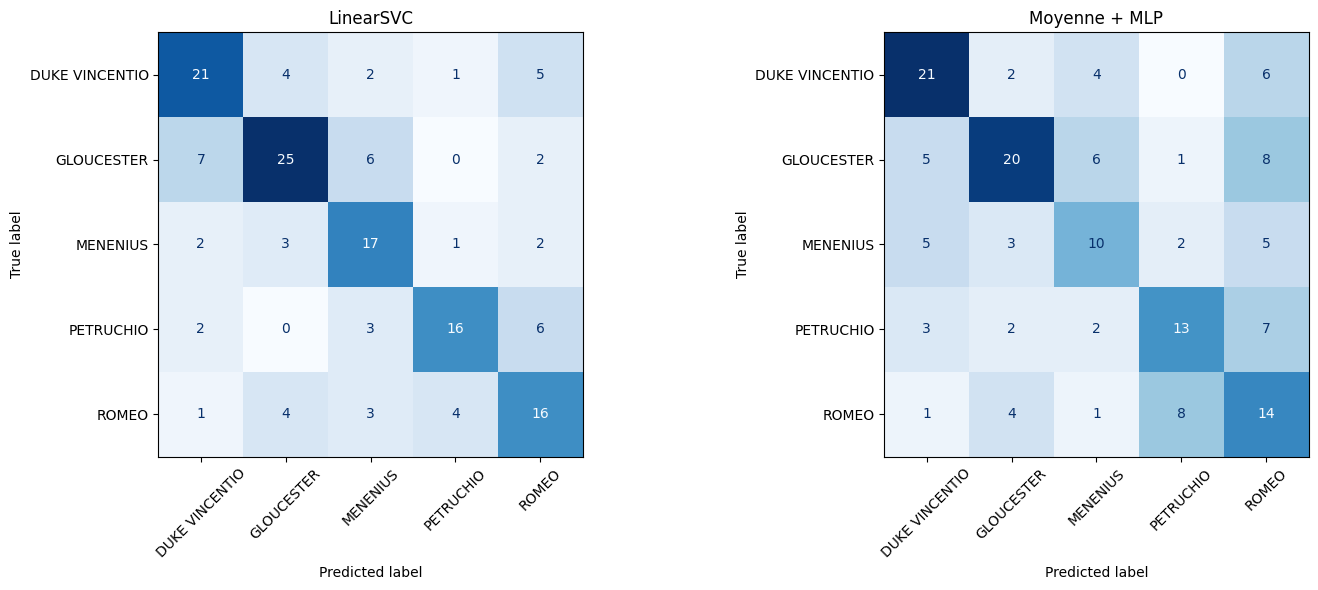

In [14]:
# le meilleur modèle ML et le meilleur DL, choisis sur la validation
meilleur_ml = max(["LogisticRegression", "LinearSVC"], key=lambda n: resultats[n]["f1_val"])
meilleur_dl = max(["Moyenne + MLP", "GRU"], key=lambda n: resultats[n]["f1_val"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, nom in zip(axes, [meilleur_ml, meilleur_dl]):
    p = resultats[nom]["preds_test"][0]          # première graine pour le DL
    ConfusionMatrixDisplay.from_predictions(
        yte, p, display_labels=classes, ax=ax, cmap="Blues",
        xticks_rotation=45, colorbar=False)
    ax.set_title(nom)
    print(nom)
    print(classification_report(yte, p, target_names=classes, zero_division=0))
plt.tight_layout()
plt.show()

In [15]:
# les répliques où le ML et le DL ne répondent pas pareil
comparaison = pd.DataFrame({
    "replique": X_test.values,
    "vrai": classes[yte],
    "ML": classes[resultats[meilleur_ml]["preds_test"][0]],
    "DL": classes[resultats[meilleur_dl]["preds_test"][0]],
})
for titre, filtre in [
    ("ML juste, DL faux", (comparaison.ML == comparaison.vrai) & (comparaison.DL != comparaison.vrai)),
    ("DL juste, ML faux", (comparaison.DL == comparaison.vrai) & (comparaison.ML != comparaison.vrai)),
]:
    sous = comparaison[filtre]
    print(f"\n=== {titre} : {len(sous)} cas ===")
    for _, l in sous.head(3).iterrows():
        print(f"[vrai {l.vrai} | ML {l.ML} | DL {l.DL}] {l.replique[:300]}")


=== ML juste, DL faux : 26 cas ===
[vrai MENENIUS | ML MENENIUS | DL DUKE VINCENTIO] Cannot be! We have record that very well it can, And three examples of the like have been Within my age. But reason with the fellow, Before you punish him, where he heard this, Lest you shall chance to whip your information And beat the messenger who bids beware Of what is to be dreaded.
[vrai GLOUCESTER | ML GLOUCESTER | DL MENENIUS] Yet had not we determined he should die, Until your lordship came to see his death; Which now the loving haste of these our friends, Somewhat against our meaning, have prevented: Because, my lord, we would have had you heard The traitor speak, and timorously confess The manner and the purpose of his
[vrai MENENIUS | ML MENENIUS | DL GLOUCESTER] Consider this: he has been bred i' the wars Since he could draw a sword, and is ill school'd In bolted language; meal and bran together He throws without distinction. Give me leave, I'll go to him, and undertake to bring him Where

## Analyse

**1. Quelle famille gagne ? L'écart dépasse-t-il la variation entre graines ?**
Le ML. Sur le test, LinearSVC atteint un F1 macro de 0,619 et la régression logistique 0,606, contre 0,437 ± 0,074 pour Moyenne + MLP et 0,349 ± 0,051 pour le GRU (baseline : 0,083). L'écart entre LinearSVC et le meilleur DL (0,18) vaut plus de deux écarts-types : il ne s'explique pas par le hasard de l'initialisation.

**2. Le gain justifie-t-il les paramètres et le temps de calcul ?**
Il n'y a pas de gain. Moyenne + MLP a environ 6 fois plus de paramètres que LinearSVC (89 925 contre 14 695) et le GRU environ 9 fois plus (136 005), pour de moins bons scores. LinearSVC prend 0,2 s en testant 5 valeurs de C, contre 5 à 6 s pour un seul entraînement DL, même sur GPU.

**3. L'ordre des mots apporte-t-il quelque chose ?**
Non, pas ici : le GRU fait moins bien que la moyenne (0,349 contre 0,437), et son sur-apprentissage est plus fort. Avec seulement 486 exemples d'entraînement et 3 graines, on ne peut pas en conclure que l'ordre des mots est inutile en général.

**4. Quelles confusions persistent ? Pourquoi ?**
Dans les deux matrices (LinearSVC / Moyenne + MLP, graine 0), on retrouve Gloucester pris pour Duke Vincentio (7 / 5) ou Menenius (6 / 6), Petruchio pris pour Romeo (6 / 7), Duke Vincentio pour Romeo (5 / 6) et Romeo pour Petruchio (4 / 8). Une explication probable : beaucoup de répliques sont courtes et générales, et certains personnages ont un vocabulaire ou un registre proche. Sur la graine 0, le ML est seul à avoir juste 26 fois, contre 9 fois pour le DL.